# 16 — Structure Ablation: Graph Topology & Edge Features

This notebook isolates two specific design choices behind this project's "physics-informed"
claim, which have never been tested in isolation:

1. **Does the CONFIRMED anatomical 4-cycle adjacency (LCA-LPA-MPA-MCA-LCA) matter, specifically**
   — rather than any graph structure at all?
2. **Does conditioning attention on physics-informed edge features** (centroid distance +
   thermal gradient) matter — rather than plain unweighted edges?

Four graph-only configurations are trained and evaluated through the *same* 5-fold
patient-level CV structure used in Phase 13 (`12_cross_validation.ipynb`), so all four are
directly comparable to each other and to the project's other CV-based results:

| Config | Topology | Edge features | Tests |
|---|---|---|---|
| A. `base_real` | confirmed 4-cycle | real (distance, thermal gradient) | replicates `graph_only_base` from Phase 12, now properly 5-fold CV'd |
| B. `selfloop_only` | no inter-node edges | n/a (self-loops only) | does ANY graph structure help over none? |
| C. `diagonal_only` | unconfirmed diagonals only (LCA-MPA, LPA-MCA) | real | does the SPECIFIC confirmed adjacency matter vs. the unconfirmed alternative? |
| D. `base_no_edgefeat` | confirmed 4-cycle | zeroed `[0.0, 0.0]` | does edge-feature CONDITIONING itself matter, independent of topology? |

All 4 configs use `use_graph_branch=True, use_image_branch=False` (graph-only mode), since
Phase 12 already showed the graph branch carries most of the signal on its own — isolating it
avoids CNN-branch noise in this specific test.

**Why there's no "fully scrambled cycle" control:** with only 4 nodes and 6 possible undirected
edges, any alternative 4-edge Hamiltonian cycle necessarily shares exactly 2 of its 4 edges with
the confirmed cycle — a combinatorial fact, not a design choice — so a "completely wrong but
same-shape" cycle control isn't achievable on this graph size. Configs B and C above are the
cleanest achievable alternatives instead.

**Data is READ ONLY in this notebook** — nothing under `data/processed/` is ever written to.
Only new checkpoints (`checkpoints/structure_*`) and new result files
(`results/structure_ablation_*`) are produced.

**A note on this notebook's own task spec:** the imports list in the original task description
named `build_model`, `train_one_epoch`, and `evaluate` from `src.train`, but Section 6 below
needs the full early-stopping training loop, which lives in `train_model` (also in
`src.train`, saved there in Phase 10). This is the same missing-import gap that showed up in
Phase 13's prompt for the identical reason — `train_model` is imported alongside the other three
here so Section 6 actually runs, and it's called out explicitly rather than silently patched.

In [1]:
# === IMPORTS ===
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)

# Add project root to sys.path so `src` is importable from this notebook's location
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.model import DualBranchGAT
from src.train import build_model, train_one_epoch, evaluate, train_model  # train_model added, see note above
from src.mc_dropout import mc_dropout_predict

print("Imports OK.")

Imports OK.


## Section 1 — Setup

Seed everything, detect the compute device, and load the three read-only source files this
notebook needs: `subject_metadata.csv` (for building this notebook's own 5 folds),
`graph_manifest.csv` (to enumerate every subject+foot `.npz` file), and
`normalization_stats.json` (Phase 7's train-derived node-feature z-score stats, reused exactly
as-is — this notebook does not recompute normalization statistics).

In [2]:
print("=== SECTION 1: Setup ===")

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

DATA_DIR = Path("data/processed")
CHECKPOINTS_DIR = Path("checkpoints")
RESULTS_DIR = Path("results")
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

subject_metadata_df = pd.read_csv(DATA_DIR / "subject_metadata.csv")
graph_manifest_df = pd.read_csv(DATA_DIR / "graph_manifest.csv")
with open(DATA_DIR / "normalization_stats.json") as f:
    normalization_stats = json.load(f)

print(f"subject_metadata_df shape: {subject_metadata_df.shape}")
print(f"graph_manifest_df shape:   {graph_manifest_df.shape}")
print(f"normalization_stats keys:  {list(normalization_stats.keys())}")
print(f"node_feature_names:        {normalization_stats.get('node_feature_names')}")

=== SECTION 1: Setup ===
Using device: cuda
subject_metadata_df shape: (167, 19)
graph_manifest_df shape:   (334, 9)
normalization_stats keys:  ['node_feature_names', 'node_feature_mean', 'node_feature_std', 'raw_tissue_mean', 'raw_tissue_std', 'relative_tissue_mean', 'relative_tissue_std', 'computed_from_split', 'train_subject_foot_count']
node_feature_names:        ['mean_abs_temp', 'std_abs_temp', 'mean_rel_temp', 'pixel_count', 'centroid_row_norm', 'centroid_col_norm']


## Section 2 — Building the 4 Edge Topologies

Topology is **fixed and identical for every subject** — only the per-subject edge feature
*values* differ (computed in the per-subject function below). `NODE_ORDER` follows Phase 6's
confirmed convention: `0=LCA, 1=LPA, 2=MPA, 3=MCA`, with the confirmed cycle being `0-1-2-3-0`.

- `base_real`: the confirmed 4-cycle, 8 directed edges — `(0,1),(1,0),(1,2),(2,1),(2,3),(3,2),(3,0),(0,3)`.
- `selfloop_only`: **empty** edge_index, shape `(2,0)`. The model's own dense-graph conversion
  (Phase 8's `sparse_to_dense_graph`) always adds self-loops regardless of input edges, so an
  empty edge_index correctly yields a self-loops-only graph with no extra code needed.
- `diagonal_only`: the 2 *unconfirmed* diagonal adjacencies only, 4 directed edges —
  `(0,2),(2,0),(1,3),(3,1)`.
- `base_no_edgefeat`: **same** edge_index as `base_real`, but `edge_attr` is forced to
  `[0.0, 0.0]` for every one of the 8 directed edges (self-loops are already `[0.0, 0.0]` by the
  model's own construction, so this makes every edge — real and self-loop — carry zero
  information).

The per-subject edge-feature function below reproduces Phase 6's exact formula: `distance` =
Euclidean distance between the two nodes' `(centroid_row_norm, centroid_col_norm)` values
(raw node_features columns 4, 5), `temp_gradient` = absolute difference of the two nodes'
`mean_abs_temp` (raw node_features column 0). It always operates on the **raw** (not
normalized) node features, exactly as Phase 6 did.

In [3]:
print("=== SECTION 2: Building the 4 Edge Topologies ===")

NODE_ORDER = ["LCA", "LPA", "MPA", "MCA"]  # indices 0, 1, 2, 3
print(f"NODE_ORDER: {NODE_ORDER}")

EDGE_INDEX_BASE_REAL = np.array(
    [[0, 1, 1, 2, 2, 3, 3, 0],
     [1, 0, 2, 1, 3, 2, 0, 3]],
    dtype=np.int64,
)

EDGE_INDEX_SELFLOOP_ONLY = np.zeros((2, 0), dtype=np.int64)

EDGE_INDEX_DIAGONAL_ONLY = np.array(
    [[0, 2, 1, 3],
     [2, 0, 3, 1]],
    dtype=np.int64,
)

# base_no_edgefeat uses the SAME topology as base_real; only edge_attr differs (zeroed),
# handled at the Dataset level in Section 3, not here.
EDGE_INDEX_BASE_NO_EDGEFEAT = EDGE_INDEX_BASE_REAL

TOPOLOGY_NAMES = ["base_real", "selfloop_only", "diagonal_only", "base_no_edgefeat"]

TOPOLOGY_EDGE_INDEX = {
    "base_real": EDGE_INDEX_BASE_REAL,
    "selfloop_only": EDGE_INDEX_SELFLOOP_ONLY,
    "diagonal_only": EDGE_INDEX_DIAGONAL_ONLY,
    "base_no_edgefeat": EDGE_INDEX_BASE_NO_EDGEFEAT,
}

for name in TOPOLOGY_NAMES:
    ei = TOPOLOGY_EDGE_INDEX[name]
    print(f"\nedge_index for '{name}', shape {ei.shape}:")
    print(ei)


def compute_edge_features(node_features_raw, edge_index):
    '''
    Phase 6's exact per-edge feature formula, applied here to whichever topology's
    edge_index is passed in.

    node_features_raw: (4, 6) RAW (not normalized) node feature matrix, column order
        [mean_abs_temp, std_abs_temp, mean_rel_temp, pixel_count,
         centroid_row_norm, centroid_col_norm]
    edge_index: (2, E) int array of directed edges

    Returns edge_attr: (E, 2) float array of [distance, temp_gradient] per edge.
    '''
    num_edges = edge_index.shape[1]
    edge_attr = np.zeros((num_edges, 2), dtype=np.float32)
    for e in range(num_edges):
        i, j = edge_index[0, e], edge_index[1, e]
        centroid_i = node_features_raw[i, 4:6]
        centroid_j = node_features_raw[j, 4:6]
        distance = np.linalg.norm(centroid_i - centroid_j)
        temp_i = node_features_raw[i, 0]
        temp_j = node_features_raw[j, 0]
        temp_gradient = abs(temp_i - temp_j)
        edge_attr[e, 0] = distance
        edge_attr[e, 1] = temp_gradient
    return edge_attr


print("\ncompute_edge_features() defined — operates on RAW node features, matches Phase 6's formula exactly.")

=== SECTION 2: Building the 4 Edge Topologies ===
NODE_ORDER: ['LCA', 'LPA', 'MPA', 'MCA']

edge_index for 'base_real', shape (2, 8):
[[0 1 1 2 2 3 3 0]
 [1 0 2 1 3 2 0 3]]

edge_index for 'selfloop_only', shape (2, 0):
[]

edge_index for 'diagonal_only', shape (2, 4):
[[0 2 1 3]
 [2 0 3 1]]

edge_index for 'base_no_edgefeat', shape (2, 8):
[[0 1 1 2 2 3 3 0]
 [1 0 2 1 3 2 0 3]]

compute_edge_features() defined — operates on RAW node features, matches Phase 6's formula exactly.


## Section 3 — Lightweight Graph-Only Dataset

`GraphOnlyDataset` is defined **in this notebook only** (not added to `src/dataset.py`, per the
task spec) since it's much lighter than `PlantarThermographyDataset` — it never touches the
raw/relative/colormap image arrays, only the 4-node graph.

Per `__getitem__`: loads that row's `.npz`, extracts raw `node_features` (4,6), normalizes it
via z-score using `normalization_stats` (Phase 7's train-derived mean/std — **never** skip this,
per the task spec, since an unnormalized tensor would silently produce a working-but-meaningless
model), computes this dataset's topology's `edge_attr` from the *raw* (pre-normalization) node
features, and returns a dict whose keys match exactly what `DualBranchGAT.forward` expects when
`use_image_branch=False`. `edge_index_diag`/`edge_attr_diag` are simple duplicates of the
`_base` versions — they exist only so the batch dict's shape matches convention; they're never
actually used, since every forward call in this notebook uses `graph_topology='base'`.

In [4]:
class GraphOnlyDataset(Dataset):
    '''
    Lightweight graph-only dataset for the structure ablation. Loads only the per-subject
    node features and applies ONE of the 4 candidate edge topologies (fixed at construction
    time) -- does NOT load raw/relative/colormap images, unlike PlantarThermographyDataset
    in src/dataset.py.
    '''

    def __init__(self, rows, normalization_stats, topology_name):
        assert topology_name in TOPOLOGY_EDGE_INDEX, f"Unknown topology_name: {topology_name}"
        self.rows = rows  # list of (subject_id, foot_side, npz_path)
        self.topology_name = topology_name
        self.edge_index = TOPOLOGY_EDGE_INDEX[topology_name]
        self.node_mean = np.array(normalization_stats["node_feature_mean"], dtype=np.float32)
        self.node_std = np.array(normalization_stats["node_feature_std"], dtype=np.float32)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        subject_id, foot_side, npz_path = self.rows[idx]
        data = np.load(npz_path, allow_pickle=True)
        node_features_raw = data["node_features"].astype(np.float32)  # (4, 6), RAW
        group = str(data["group"])

        edge_index = self.edge_index

        if self.topology_name == "selfloop_only":
            edge_attr = np.zeros((0, 2), dtype=np.float32)
        elif self.topology_name == "base_no_edgefeat":
            # same topology as base_real, but every real edge's feature forced to [0.0, 0.0]
            edge_attr = np.zeros((edge_index.shape[1], 2), dtype=np.float32)
        else:
            edge_attr = compute_edge_features(node_features_raw, edge_index)

        node_features_norm = (node_features_raw - self.node_mean) / self.node_std

        label = 1 if group == "DM" else 0

        return {
            "node_features": torch.from_numpy(node_features_norm).float(),
            "edge_index_base": torch.from_numpy(edge_index).long(),
            "edge_attr_base": torch.from_numpy(edge_attr).float(),
            "edge_index_diag": torch.from_numpy(edge_index).long(),   # duplicate, unused
            "edge_attr_diag": torch.from_numpy(edge_attr).float(),    # duplicate, unused
            "label": torch.tensor(label, dtype=torch.int64),
            "subject_id": subject_id,
            "foot_side": foot_side,
            "group": group,
        }


def get_rows_for_subjects(manifest_df, subject_ids):
    '''Both feet for every subject_id in subject_ids, as (subject_id, foot_side, npz_path) tuples.'''
    subject_ids_set = set(subject_ids)
    subset = manifest_df[manifest_df["subject_id"].isin(subject_ids_set)]
    return list(zip(subset["subject_id"], subset["foot_side"], subset["npz_path"]))


print("=== SECTION 3: GraphOnlyDataset defined ===")
_sample_rows = get_rows_for_subjects(graph_manifest_df, graph_manifest_df["subject_id"].unique()[:2])
_sample_ds = GraphOnlyDataset(_sample_rows, normalization_stats, topology_name="base_real")
_sample_item = _sample_ds[0]
print("Sample item keys:", list(_sample_item.keys()))
print("node_features shape:", tuple(_sample_item["node_features"].shape))
print("edge_index_base shape:", tuple(_sample_item["edge_index_base"].shape))
print("edge_attr_base shape:", tuple(_sample_item["edge_attr_base"].shape))

=== SECTION 3: GraphOnlyDataset defined ===
Sample item keys: ['node_features', 'edge_index_base', 'edge_attr_base', 'edge_index_diag', 'edge_attr_diag', 'label', 'subject_id', 'foot_side', 'group']
node_features shape: (4, 6)
edge_index_base shape: (2, 8)
edge_attr_base shape: (8, 2)


## Section 4 — Mandatory Smoke Test (before any training)

Build a fresh `DualBranchGAT(use_graph_branch=True, use_image_branch=False)`, construct one
small batch (`batch_size=4`) from a `GraphOnlyDataset` using the `base_real` topology, and call
`model(batch, graph_topology='base', image_key=None)` inside `torch.no_grad()`.

If this raises a `KeyError` or `AttributeError`, that means `DualBranchGAT.forward` needs a
batch key beyond what Section 3 provides even with `use_image_branch=False` — the cell below
catches exactly that, adds a harmless zero-tensor placeholder for whatever key is missing (a
dummy `colormap_image` of zeros is the most likely candidate, per the task spec), retries once,
and records what had to be added in `smoke_test_fix_notes` so Section 12's final summary can
report it truthfully either way.

In [5]:
print("=== SECTION 4: Mandatory Smoke Test ===")

GRAPH_ONLY_MODEL_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": False,
    "image_in_channels": 3,   # unused since use_image_branch=False; kept for build_model's expected keys
    "graph_topology": "base",
    "image_key": None,
}

smoke_test_fix_notes = []

smoke_model = build_model(GRAPH_ONLY_MODEL_CONFIG)
smoke_model.to(device)
smoke_model.eval()

_smoke_rows = get_rows_for_subjects(graph_manifest_df, graph_manifest_df["subject_id"].unique()[:4])
_smoke_dataset = GraphOnlyDataset(_smoke_rows, normalization_stats, topology_name="base_real")
_smoke_loader = DataLoader(_smoke_dataset, batch_size=4, shuffle=False)
_smoke_batch = next(iter(_smoke_loader))
_smoke_batch = {
    k: (v.to(device) if isinstance(v, torch.Tensor) else v) for k, v in _smoke_batch.items()
}

try:
    with torch.no_grad():
        _smoke_output = smoke_model(_smoke_batch, graph_topology="base", image_key=None)
    print(f"Smoke test PASSED on first attempt.")
    print(f"Output shape: {tuple(_smoke_output.shape)}, dtype: {_smoke_output.dtype}")
    assert not torch.isnan(_smoke_output).any(), "NaNs in smoke test output!"
    print("No NaNs in output. No fallback fix was needed.")
except (KeyError, AttributeError) as e:
    print(f"Smoke test raised {type(e).__name__}: {e}")
    print("Applying fallback fix: adding a harmless dummy 'colormap_image' zero-tensor to the batch.")
    B = _smoke_batch["node_features"].shape[0]
    _smoke_batch["colormap_image"] = torch.zeros(B, 3, 208, 96, dtype=torch.float32, device=device)
    smoke_test_fix_notes.append(
        "Added dummy 'colormap_image' zero-tensor (shape (B,3,208,96)) to the batch dict "
        "because DualBranchGAT.forward required it even with use_image_branch=False. "
        f"Original error: {type(e).__name__}: {e}"
    )
    with torch.no_grad():
        _smoke_output = smoke_model(_smoke_batch, graph_topology="base", image_key=None)
    print(f"Smoke test PASSED after fallback fix.")
    print(f"Output shape: {tuple(_smoke_output.shape)}, dtype: {_smoke_output.dtype}")
    assert not torch.isnan(_smoke_output).any(), "NaNs in smoke test output after fallback fix!"
    print("No NaNs in output after fallback fix.")

print(f"\nsmoke_test_fix_notes: {smoke_test_fix_notes if smoke_test_fix_notes else '(none — no fix was needed)'}")

=== SECTION 4: Mandatory Smoke Test ===
Smoke test PASSED on first attempt.
Output shape: (4,), dtype: torch.float32
No NaNs in output. No fallback fix was needed.

smoke_test_fix_notes: (none — no fix was needed)


**On the expected outcome of the smoke test above:** since `image_key=None` and
`use_image_branch=False`, Phase 8's `DualBranchGAT.forward` design (`(b) picks batch[image_key]
and runs ImageBranch if enabled`) should skip the image-branch code path entirely, so this smoke
test is expected to **pass on the first attempt** with no fallback fix required. The try/except
fallback above is still included exactly per the task spec's instructions, as a safety net —
if it ever *does* trigger, `smoke_test_fix_notes` documents precisely what was added and why,
and that note is carried through to Section 12's final summary and `structure_ablation_summary.json`
rather than being silently absorbed.

## Section 5 — Reproduce the Exact Same 5 Folds as Phase 13

Identical method to Phase 13 (`12_cross_validation.ipynb`): `subject_ids_all`/`groups_all` read
from `subject_metadata.csv` in **original row order** (never sorted), then
`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on `Group`, with each fold's
train-portion further split 90/10 (stratified, `random_state=42`) into train/val.

This does **not** need to exactly match `cv_pooled_predictions.csv` subject-for-subject to be
valid (this is a different, graph-only model) — but using the identical fold-construction code
keeps this notebook's comparison methodologically consistent with Phase 13's CV structure.

In [6]:
print("=== SECTION 5: Reproducing Phase 13's 5 Folds ===")

subject_ids_all = subject_metadata_df["Subject"].values
groups_all = subject_metadata_df["Group"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

folds = []
for fold_idx, (train_val_idx, test_idx) in enumerate(skf.split(subject_ids_all, groups_all)):
    train_val_subjects = subject_ids_all[train_val_idx]
    train_val_groups = groups_all[train_val_idx]
    test_subjects = subject_ids_all[test_idx]

    train_subjects, val_subjects = train_test_split(
        train_val_subjects,
        test_size=0.10,
        stratify=train_val_groups,
        random_state=42,
    )

    folds.append({
        "fold_idx": fold_idx,
        "train_subjects": train_subjects,
        "val_subjects": val_subjects,
        "test_subjects": test_subjects,
    })

    print(
        f"Fold {fold_idx}: train={len(train_subjects)}, "
        f"val={len(val_subjects)}, test={len(test_subjects)}"
    )

test_sizes = [len(f["test_subjects"]) for f in folds]
print(f"\nTest fold sizes: {test_sizes}")
print("Expected to match Phase 13's test sizes: [34, 34, 33, 33, 33] (order may vary by fold index).")
print(f"Sum of test sizes: {sum(test_sizes)} (should be 167)")

=== SECTION 5: Reproducing Phase 13's 5 Folds ===
Fold 0: train=119, val=14, test=34
Fold 1: train=119, val=14, test=34
Fold 2: train=120, val=14, test=33
Fold 3: train=120, val=14, test=33
Fold 4: train=120, val=14, test=33

Test fold sizes: [34, 34, 33, 33, 33]
Expected to match Phase 13's test sizes: [34, 34, 33, 33, 33] (order may vary by fold index).
Sum of test sizes: 167 (should be 167)


## Section 6 — Train 4 Topologies × 5 Folds = 20 Runs

For each of the 4 topology configs, for each of the 5 folds: build `GraphOnlyDataset` instances
for train/val/test from `graph_manifest.csv` rows filtered to that fold's subject_ids and that
topology, wrap in `DataLoader`s (`batch_size=16`, `shuffle=True` for train only), recompute class
weights from that fold's train subjects (same inverse-frequency formula as Phase 10:
`weight_c = N_train / (2 * count_c)`), build `BCEWithLogitsLoss(pos_weight=dm_weight)`, and train
via `train_model(...)` with the exact same hyperparameters as every other phase's training runs
(`max_epochs=150, patience=20, lr=1e-3, weight_decay=1e-4`).

Since `graph_topology='base'` is always passed to `forward()` regardless of which of the 4
configs is being trained, the topology choice is entirely baked into
`edge_index_base`/`edge_attr_base` by `GraphOnlyDataset` itself — this is 20 short, small
training runs (graph-only models are ~6.5K params per Phase 12), so it should complete quickly
even on a modest GPU.

In [7]:
def compute_fold_class_weights(train_subjects, subject_metadata_df):
    '''Inverse-frequency class weights from this fold's TRAIN subjects only (Phase 10's formula).'''
    train_meta = subject_metadata_df[subject_metadata_df["Subject"].isin(train_subjects)]
    counts = train_meta["Group"].value_counts()
    n_train = len(train_meta)
    weight_control = n_train / (2 * counts["Control"])
    weight_dm = n_train / (2 * counts["DM"])
    return weight_control, weight_dm


print("=== SECTION 6: Training 4 Topologies x 5 Folds = 20 Runs ===")
training_records = []

for t_idx, topology_name in enumerate(TOPOLOGY_NAMES, start=1):
    for fold in folds:
        fold_idx = fold["fold_idx"]
        print(f"\n--- topology {t_idx}/4 ({topology_name}), fold {fold_idx + 1}/5 ---")

        train_rows = get_rows_for_subjects(graph_manifest_df, fold["train_subjects"])
        val_rows = get_rows_for_subjects(graph_manifest_df, fold["val_subjects"])
        test_rows = get_rows_for_subjects(graph_manifest_df, fold["test_subjects"])

        train_ds = GraphOnlyDataset(train_rows, normalization_stats, topology_name)
        val_ds = GraphOnlyDataset(val_rows, normalization_stats, topology_name)
        test_ds = GraphOnlyDataset(test_rows, normalization_stats, topology_name)

        train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)
        test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

        weight_control, weight_dm = compute_fold_class_weights(fold["train_subjects"], subject_metadata_df)
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm, dtype=torch.float32))

        config = {
            "use_graph_branch": True,
            "use_image_branch": False,
            "image_in_channels": 3,  # unused
            "graph_topology": "base",  # topology is baked into the dataset; always 'base' here
            "image_key": None,
        }

        checkpoint_path = str(CHECKPOINTS_DIR / f"structure_{topology_name}_fold{fold_idx}_best.pt")

        history, best_epoch, best_val_roc_auc = train_model(
            config,
            train_loader,
            val_loader,
            criterion,
            device,
            max_epochs=150,
            patience=20,
            lr=1e-3,
            weight_decay=1e-4,
            checkpoint_path=checkpoint_path,
        )

        print(f"  best_epoch={best_epoch}, best_val_roc_auc={best_val_roc_auc:.4f}")

        training_records.append({
            "topology": topology_name,
            "fold_idx": fold_idx,
            "checkpoint_path": checkpoint_path,
            "best_epoch": best_epoch,
            "best_val_roc_auc": best_val_roc_auc,
            "weight_control": weight_control,
            "weight_dm": weight_dm,
            "val_loader": val_loader,
            "test_loader": test_loader,
        })

print(f"\nCompleted {len(training_records)} / 20 expected training runs.")

=== SECTION 6: Training 4 Topologies x 5 Folds = 20 Runs ===

--- topology 1/4 (base_real), fold 1/5 ---
epoch    0 | train_loss=0.4758 val_loss=0.4878 val_roc_auc=0.6938 val_bal_acc=0.6500 *
epoch    5 | train_loss=0.3044 val_loss=0.4592 val_roc_auc=0.7063 val_bal_acc=0.7000 *
epoch    6 | train_loss=0.3030 val_loss=0.4512 val_roc_auc=0.7375 val_bal_acc=0.7000 *
epoch    9 | train_loss=0.2844 val_loss=0.4222 val_roc_auc=0.7438 val_bal_acc=0.6875 *
epoch   10 | train_loss=0.2792 val_loss=0.4334 val_roc_auc=0.7312 val_bal_acc=0.6625
epoch   15 | train_loss=0.2720 val_loss=0.4407 val_roc_auc=0.7312 val_bal_acc=0.6750
epoch   16 | train_loss=0.2685 val_loss=0.4180 val_roc_auc=0.7750 val_bal_acc=0.6125 *
epoch   19 | train_loss=0.2579 val_loss=0.4056 val_roc_auc=0.8000 val_bal_acc=0.6750 *
epoch   20 | train_loss=0.2624 val_loss=0.4014 val_roc_auc=0.8250 val_bal_acc=0.6750 *
epoch   25 | train_loss=0.2539 val_loss=0.4319 val_roc_auc=0.7500 val_bal_acc=0.6125
epoch   30 | train_loss=0.2375 

## Section 7 — Per-Fold Test Evaluation

For each of the 20 checkpoints: reload it, compute that fold's own Youden's-J-optimal threshold
from its own val predictions (same procedure as Phase 11/13), run `mc_dropout_predict(T=30,
graph_topology='base', image_key=None)` on that fold's test subjects, and compute
**subject-level** metrics (averaging both feet's `mc_mean_prob` per subject). Each topology's
5 folds' out-of-fold subject-level predictions are pooled into one 167-subject set, matching
Phase 13's pooling convention exactly.

In [8]:
def youden_optimal_threshold(true_labels, probs):
    fpr, tpr, thresholds = roc_curve(true_labels, probs)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    return float(thresholds[best_idx])


print("=== SECTION 7: Per-Fold Test Evaluation ===")

topology_fold_metrics = {t: [] for t in TOPOLOGY_NAMES}
topology_pooled_predictions = {t: [] for t in TOPOLOGY_NAMES}

for record in training_records:
    topology_name = record["topology"]
    fold_idx = record["fold_idx"]

    eval_model = build_model(GRAPH_ONLY_MODEL_CONFIG)
    eval_model.load_state_dict(torch.load(record["checkpoint_path"], map_location=device))
    eval_model.to(device)
    eval_model.eval()

    # --- Youden's J optimal threshold from this fold's own val predictions ---
    val_probs, val_labels = [], []
    with torch.no_grad():
        for batch in record["val_loader"]:
            batch_dev = {k: (v.to(device) if isinstance(v, torch.Tensor) else v) for k, v in batch.items()}
            logits = eval_model(batch_dev, graph_topology="base", image_key=None)
            probs = torch.sigmoid(logits).cpu().numpy()
            val_probs.extend(probs.tolist())
            val_labels.extend(batch["label"].cpu().numpy().tolist())
    threshold = youden_optimal_threshold(val_labels, val_probs)

    # --- MC-Dropout (T=30) on this fold's test subjects ---
    all_mean_prob, all_subject_id, all_foot_side, all_label = [], [], [], []
    for batch in record["test_loader"]:
        batch_dev = {k: (v.to(device) if isinstance(v, torch.Tensor) else v) for k, v in batch.items()}
        mc_results = mc_dropout_predict(
            eval_model, batch_dev, T=30, graph_topology="base", image_key=None
        )
        all_mean_prob.extend(mc_results["mean_prob"].detach().cpu().numpy().tolist())
        all_subject_id.extend(batch["subject_id"])
        all_foot_side.extend(batch["foot_side"])
        all_label.extend(batch["label"].cpu().numpy().tolist())

    foot_df = pd.DataFrame({
        "subject_id": all_subject_id,
        "foot_side": all_foot_side,
        "true_label": all_label,
        "mc_mean_prob": all_mean_prob,
    })

    subject_df = foot_df.groupby("subject_id").agg(
        true_label=("true_label", "first"),
        mc_mean_prob=("mc_mean_prob", "mean"),
    ).reset_index()
    subject_df["pred_label"] = (subject_df["mc_mean_prob"] >= threshold).astype(int)

    fold_roc_auc = roc_auc_score(subject_df["true_label"], subject_df["mc_mean_prob"])
    fold_bal_acc = balanced_accuracy_score(subject_df["true_label"], subject_df["pred_label"])
    fold_f1 = f1_score(subject_df["true_label"], subject_df["pred_label"])
    fold_acc = accuracy_score(subject_df["true_label"], subject_df["pred_label"])

    topology_fold_metrics[topology_name].append({
        "fold_idx": fold_idx,
        "threshold": threshold,
        "roc_auc": fold_roc_auc,
        "balanced_accuracy": fold_bal_acc,
        "f1": fold_f1,
        "accuracy": fold_acc,
        "n_subjects": len(subject_df),
    })

    for _, row in subject_df.iterrows():
        topology_pooled_predictions[topology_name].append({
            "subject_id": row["subject_id"],
            "true_label": int(row["true_label"]),
            "mc_mean_prob": float(row["mc_mean_prob"]),
            "pred_label_optimal": int(row["pred_label"]),
        })

    print(
        f"[{topology_name}] fold {fold_idx}: threshold={threshold:.4f}, "
        f"roc_auc={fold_roc_auc:.4f}, bal_acc={fold_bal_acc:.4f}, "
        f"f1={fold_f1:.4f}, acc={fold_acc:.4f}, n_subjects={len(subject_df)}"
    )

=== SECTION 7: Per-Fold Test Evaluation ===
[base_real] fold 0: threshold=0.3434, roc_auc=0.9511, bal_acc=0.8689, f1=0.9412, acc=0.9118, n_subjects=34
[base_real] fold 1: threshold=0.4096, roc_auc=0.8489, bal_acc=0.5356, f1=0.8421, acc=0.7353, n_subjects=34
[base_real] fold 2: threshold=0.4246, roc_auc=0.8796, bal_acc=0.7361, f1=0.8800, acc=0.8182, n_subjects=33
[base_real] fold 3: threshold=0.6983, roc_auc=0.9167, bal_acc=0.8542, f1=0.8293, acc=0.7879, n_subjects=33
[base_real] fold 4: threshold=0.4302, roc_auc=0.8194, bal_acc=0.7083, f1=0.8000, acc=0.7273, n_subjects=33
[selfloop_only] fold 0: threshold=0.4499, roc_auc=0.9600, bal_acc=0.8689, f1=0.9412, acc=0.9118, n_subjects=34
[selfloop_only] fold 1: threshold=0.3412, roc_auc=0.8489, bal_acc=0.5356, f1=0.8421, acc=0.7353, n_subjects=34
[selfloop_only] fold 2: threshold=0.3957, roc_auc=0.8704, bal_acc=0.7222, f1=0.9057, acc=0.8485, n_subjects=33
[selfloop_only] fold 3: threshold=0.5573, roc_auc=0.9167, bal_acc=0.7917, f1=0.7368, acc

## Section 8 — Aggregate and Compare

One summary row per topology: fold-mean ± std, and pooled (167-subject, one out-of-fold
prediction per subject) `roc_auc`/`balanced_accuracy`/`f1`/`accuracy`. Pooled hard-classification
metrics reuse each subject's own fold's optimal threshold (`pred_label_optimal`) — no separate
pooled threshold is computed, matching Phase 13's convention.

In [9]:
print("=== SECTION 8: Aggregate and Compare ===")

summary_rows = []
for topology_name in TOPOLOGY_NAMES:
    fold_metrics_df = pd.DataFrame(topology_fold_metrics[topology_name])
    pooled_df = pd.DataFrame(topology_pooled_predictions[topology_name])

    pooled_roc_auc = roc_auc_score(pooled_df["true_label"], pooled_df["mc_mean_prob"])
    pooled_bal_acc = balanced_accuracy_score(pooled_df["true_label"], pooled_df["pred_label_optimal"])
    pooled_f1 = f1_score(pooled_df["true_label"], pooled_df["pred_label_optimal"])
    pooled_acc = accuracy_score(pooled_df["true_label"], pooled_df["pred_label_optimal"])

    summary_rows.append({
        "topology": topology_name,
        "fold_roc_auc_mean": fold_metrics_df["roc_auc"].mean(),
        "fold_roc_auc_std": fold_metrics_df["roc_auc"].std(),
        "fold_balanced_accuracy_mean": fold_metrics_df["balanced_accuracy"].mean(),
        "fold_balanced_accuracy_std": fold_metrics_df["balanced_accuracy"].std(),
        "fold_f1_mean": fold_metrics_df["f1"].mean(),
        "fold_f1_std": fold_metrics_df["f1"].std(),
        "fold_accuracy_mean": fold_metrics_df["accuracy"].mean(),
        "fold_accuracy_std": fold_metrics_df["accuracy"].std(),
        "pooled_roc_auc": pooled_roc_auc,
        "pooled_balanced_accuracy": pooled_bal_acc,
        "pooled_f1": pooled_f1,
        "pooled_accuracy": pooled_acc,
        "n_subjects_pooled": len(pooled_df),
    })

structure_ablation_results_df = (
    pd.DataFrame(summary_rows).sort_values("pooled_roc_auc", ascending=False).reset_index(drop=True)
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print(structure_ablation_results_df.to_string(index=False))

=== SECTION 8: Aggregate and Compare ===
        topology  fold_roc_auc_mean  fold_roc_auc_std  fold_balanced_accuracy_mean  fold_balanced_accuracy_std  fold_f1_mean  fold_f1_std  fold_accuracy_mean  fold_accuracy_std  pooled_roc_auc  pooled_balanced_accuracy  pooled_f1  pooled_accuracy  n_subjects_pooled
       base_real           0.883148          0.052409                     0.740611                    0.134592      0.858510     0.054413            0.796078           0.074780        0.889435                  0.741439   0.860656         0.796407                167
base_no_edgefeat           0.873889          0.054878                     0.764556                    0.124618      0.878440     0.034461            0.819786           0.058262        0.882149                  0.764845   0.878049         0.820359                167
   diagonal_only           0.887444          0.051509                     0.746167                    0.138110      0.873821     0.047421            0.814082    

## Section 9 — Plots

(a) Bar chart of pooled subject-level ROC-AUC per topology, with fold-to-fold std as error bars.
(b) Overlaid pooled ROC curves for all 4 topologies on one plot.

=== SECTION 9: Plots ===


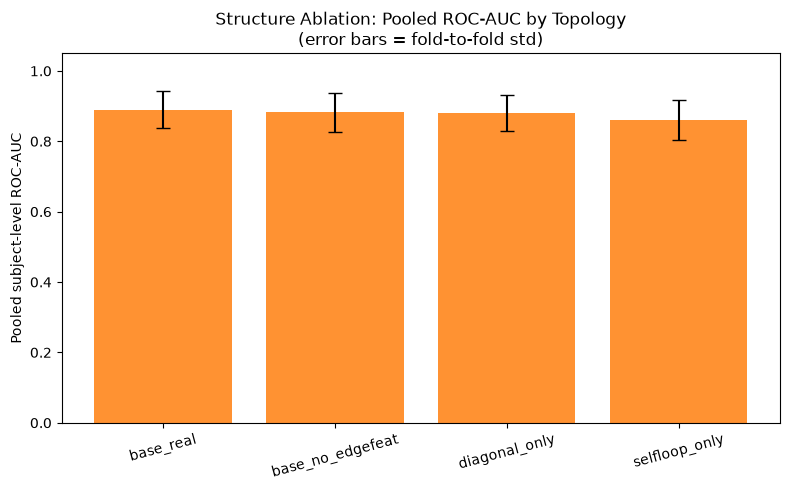

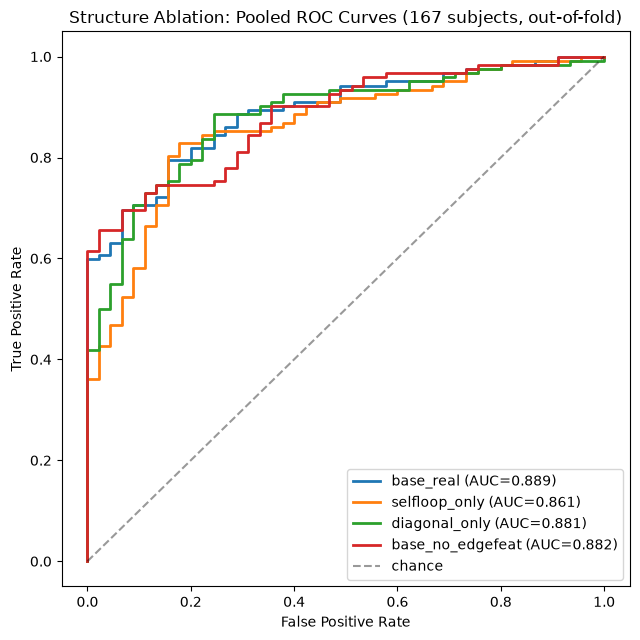

In [10]:
print("=== SECTION 9: Plots ===")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    structure_ablation_results_df["topology"],
    structure_ablation_results_df["pooled_roc_auc"],
    yerr=structure_ablation_results_df["fold_roc_auc_std"],
    capsize=5,
    color="#ff7f0e",
    alpha=0.85,
)
ax.set_ylabel("Pooled subject-level ROC-AUC")
ax.set_title("Structure Ablation: Pooled ROC-AUC by Topology\n(error bars = fold-to-fold std)")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(6.5, 6.5))
for topology_name in TOPOLOGY_NAMES:
    pooled_df = pd.DataFrame(topology_pooled_predictions[topology_name])
    fpr, tpr, _ = roc_curve(pooled_df["true_label"], pooled_df["mc_mean_prob"])
    auc_val = roc_auc_score(pooled_df["true_label"], pooled_df["mc_mean_prob"])
    ax2.plot(fpr, tpr, label=f"{topology_name} (AUC={auc_val:.3f})", linewidth=2)
ax2.plot([0, 1], [0, 1], "k--", alpha=0.4, label="chance")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("Structure Ablation: Pooled ROC Curves (167 subjects, out-of-fold)")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Section 10 — Qualitative Summary

Rendered as markdown below, auto-generated from the actual computed pooled ROC-AUC gaps rather
than left as a static template — since this notebook can't know in advance what the real numbers
will be. "Meaningful" is judged with a simple, conservative heuristic: whether the pooled AUC gap
exceeds the two configs' *combined* fold-to-fold standard deviation. This is not a formal
significance test (only 5 folds), so gaps that don't clear this bar are reported as inconclusive
rather than as evidence of no difference.

In [11]:
from IPython.display import display, Markdown

print("=== SECTION 10: Qualitative Summary ===")

results_by_topology = structure_ablation_results_df.set_index("topology")
base_row = results_by_topology.loc["base_real"]
selfloop_row = results_by_topology.loc["selfloop_only"]
diag_row = results_by_topology.loc["diagonal_only"]
noedge_row = results_by_topology.loc["base_no_edgefeat"]


def describe_gap(name_a, row_a, name_b, row_b):
    gap = row_a["pooled_roc_auc"] - row_b["pooled_roc_auc"]
    combined_std = float(np.sqrt(row_a["fold_roc_auc_std"] ** 2 + row_b["fold_roc_auc_std"] ** 2))
    meaningful = abs(gap) > combined_std
    direction = f"**{name_a}** beats **{name_b}**" if gap > 0 else f"**{name_b}** beats **{name_a}**"
    verdict = (
        "this gap is larger than the two configs' combined fold-to-fold noise, "
        "so it plausibly reflects a real difference"
        if meaningful else
        "this gap is smaller than the two configs' combined fold-to-fold noise, "
        "so it should be read as inconclusive rather than a real difference"
    )
    return gap, combined_std, direction, verdict


gap1, std1, dir1, verdict1 = describe_gap("base_real", base_row, "selfloop_only", selfloop_row)
gap2, std2, dir2, verdict2 = describe_gap("base_real", base_row, "diagonal_only", diag_row)
gap3, std3, dir3, verdict3 = describe_gap("base_real", base_row, "base_no_edgefeat", noedge_row)

summary_text = f'''
### Does graph structure help at all? (`base_real` vs. `selfloop_only`)
Pooled ROC-AUC gap: **{gap1:+.4f}** ({dir1}, combined fold std = {std1:.4f}).
{verdict1.capitalize()}.

### Does the SPECIFIC confirmed adjacency matter? (`base_real` vs. `diagonal_only`)
Pooled ROC-AUC gap: **{gap2:+.4f}** ({dir2}, combined fold std = {std2:.4f}).
{verdict2.capitalize()}.

### Do the physics-informed edge features matter, independent of topology? (`base_real` vs. `base_no_edgefeat`)
Pooled ROC-AUC gap: **{gap3:+.4f}** ({dir3}, combined fold std = {std3:.4f}).
{verdict3.capitalize()}.

---
*"Meaningful" above is a simple heuristic (gap vs. combined fold-to-fold std), not a formal
significance test — with only 5 folds per config, treat these as directional, exploratory
findings, consistent with how Phase 12/14's bootstrap-CI-based comparisons were framed.*
'''

display(Markdown(summary_text))

=== SECTION 10: Qualitative Summary ===



### Does graph structure help at all? (`base_real` vs. `selfloop_only`)
Pooled ROC-AUC gap: **+0.0286** (**base_real** beats **selfloop_only**, combined fold std = 0.0765).
This gap is smaller than the two configs' combined fold-to-fold noise, so it should be read as inconclusive rather than a real difference.

### Does the SPECIFIC confirmed adjacency matter? (`base_real` vs. `diagonal_only`)
Pooled ROC-AUC gap: **+0.0087** (**base_real** beats **diagonal_only**, combined fold std = 0.0735).
This gap is smaller than the two configs' combined fold-to-fold noise, so it should be read as inconclusive rather than a real difference.

### Do the physics-informed edge features matter, independent of topology? (`base_real` vs. `base_no_edgefeat`)
Pooled ROC-AUC gap: **+0.0073** (**base_real** beats **base_no_edgefeat**, combined fold std = 0.0759).
This gap is smaller than the two configs' combined fold-to-fold noise, so it should be read as inconclusive rather than a real difference.

---
*"Meaningful" above is a simple heuristic (gap vs. combined fold-to-fold std), not a formal
significance test — with only 5 folds per config, treat these as directional, exploratory
findings, consistent with how Phase 12/14's bootstrap-CI-based comparisons were framed.*


## Section 11 — Save Results

- `results/structure_ablation_results.csv` — the Section 8 summary table.
- `results/structure_ablation_pooled_predictions.csv` — 167 rows × (3 + 4) columns:
  `subject_id`, `group`, `true_label`, then one pooled probability column per topology.
- `results/structure_ablation_summary.json` — the results table plus run metadata.

In [12]:
print("=== SECTION 11: Saving Results ===")

structure_ablation_results_df.to_csv(RESULTS_DIR / "structure_ablation_results.csv", index=False)
print(f"Saved results/structure_ablation_results.csv, shape {structure_ablation_results_df.shape}")

pooled_wide = None
for topology_name in TOPOLOGY_NAMES:
    pdf = pd.DataFrame(topology_pooled_predictions[topology_name])[["subject_id", "true_label", "mc_mean_prob"]]
    pdf = pdf.rename(columns={"mc_mean_prob": f"{topology_name}_prob"})
    if pooled_wide is None:
        pooled_wide = pdf
    else:
        pooled_wide = pooled_wide.merge(pdf[["subject_id", f"{topology_name}_prob"]], on="subject_id", how="outer")

pooled_wide = pooled_wide.merge(
    subject_metadata_df[["Subject", "Group"]], left_on="subject_id", right_on="Subject", how="left"
)
pooled_wide = pooled_wide.rename(columns={"Group": "group"}).drop(columns=["Subject"])
pooled_wide = pooled_wide[["subject_id", "group", "true_label"] + [f"{t}_prob" for t in TOPOLOGY_NAMES]]

pooled_wide.to_csv(RESULTS_DIR / "structure_ablation_pooled_predictions.csv", index=False)
print(f"Saved results/structure_ablation_pooled_predictions.csv, shape {pooled_wide.shape}")
print("Expected shape: (167, 7)")

structure_ablation_summary = {
    "topology_configs": TOPOLOGY_NAMES,
    "n_folds": 5,
    "random_seed": 42,
    "hyperparameters": {
        "max_epochs": 150,
        "patience": 20,
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 16,
        "mc_dropout_T": 30,
    },
    "smoke_test_fix_notes": smoke_test_fix_notes,
    "results_table": structure_ablation_results_df.to_dict(orient="records"),
}
with open(RESULTS_DIR / "structure_ablation_summary.json", "w") as f:
    json.dump(structure_ablation_summary, f, indent=2, default=float)
print("Saved results/structure_ablation_summary.json")

=== SECTION 11: Saving Results ===
Saved results/structure_ablation_results.csv, shape (4, 14)
Saved results/structure_ablation_pooled_predictions.csv, shape (167, 7)
Expected shape: (167, 7)
Saved results/structure_ablation_summary.json


## Section 12 — Final Summary

In [13]:
print("=== SECTION 12: Final Summary ===")

print("\nFinal ranked results (pooled subject-level ROC-AUC descending):")
print(structure_ablation_results_df.to_string(index=False))

winner = structure_ablation_results_df.iloc[0]
runner_up = structure_ablation_results_df.iloc[1]
print(
    f"\nTop topology: {winner['topology']} "
    f"(pooled ROC-AUC={winner['pooled_roc_auc']:.4f}), "
    f"margin over next best ({runner_up['topology']}): "
    f"{winner['pooled_roc_auc'] - runner_up['pooled_roc_auc']:+.4f}"
)

print(f"\nSmoke test (Section 4): {'PASSED with a fallback fix' if smoke_test_fix_notes else 'PASSED with no fix needed'}")
for note in smoke_test_fix_notes:
    print(f" - {note}")

n_checkpoints = len(list(CHECKPOINTS_DIR.glob('structure_*_best.pt')))
print(f"\nCheckpoints saved: {n_checkpoints} / 20 expected")

result_files = [
    RESULTS_DIR / "structure_ablation_results.csv",
    RESULTS_DIR / "structure_ablation_pooled_predictions.csv",
    RESULTS_DIR / "structure_ablation_summary.json",
]
for rf in result_files:
    print(f"  {rf}: {'saved' if rf.exists() else 'MISSING'}")

issues = []
if n_checkpoints != 20:
    issues.append(f"expected 20 checkpoints, found {n_checkpoints}")
for rf in result_files:
    if not rf.exists():
        issues.append(f"missing result file: {rf}")

print(f"\nIssues found: {len(issues)}" if issues else "\nIssues found: 0")
for issue in issues:
    print(f" - {issue}")

=== SECTION 12: Final Summary ===

Final ranked results (pooled subject-level ROC-AUC descending):
        topology  fold_roc_auc_mean  fold_roc_auc_std  fold_balanced_accuracy_mean  fold_balanced_accuracy_std  fold_f1_mean  fold_f1_std  fold_accuracy_mean  fold_accuracy_std  pooled_roc_auc  pooled_balanced_accuracy  pooled_f1  pooled_accuracy  n_subjects_pooled
       base_real           0.883148          0.052409                     0.740611                    0.134592      0.858510     0.054413            0.796078           0.074780        0.889435                  0.741439   0.860656         0.796407                167
base_no_edgefeat           0.873889          0.054878                     0.764556                    0.124618      0.878440     0.034461            0.819786           0.058262        0.882149                  0.764845   0.878049         0.820359                167
   diagonal_only           0.887444          0.051509                     0.746167                    0